# Battery State of Charge Estimation

**State of charge (SOC)** is the charge level of a battery, normalised between 0 (fully discharged) and 1 (fully charged) [1].

This is a **regression problem**: given measurements of a battery's terminal voltage, current, and temperature, we predict its SOC.

## What this notebook covers
1. Preparing and visualising the battery data (voltage, current, temperature, SOC).
2. Training four regression models: polynomial regression, decision tree, random forest, and support vector regression (SVR).
3. Comparing the models using RMSE and learning curves to select the best one.
4. Testing the selected model on unseen data and assessing its performance.

## Dataset [2]
The data comes from a Simulink simulation of a battery with a Kalman-filter SOC estimator [3].

| Property | Value |
|---|---|
| Ambient temperatures | -10, 0, 10, 25 °C |
| Cycle | 9000 s charging, then 3000 s discharging, repeated for 10 hours per temperature [4] |
| SOC range | Starts at 0.5, charges up to 0.9 [4] |
| Inputs | Voltage, current, temperature |
| Target | SOC |


## References
\[1\] ‘What Is Battery State of Charge?’ Accessed: Nov. 11, 2026. [Online]. Available: https://www.mathworks.com/discovery/battery-state-of-charge.html

\[2\] ‘Battery State-of-Charge Estimation - MATLAB & Simulink’. Accessed: Nov. 11, 2026. [Online]. Available: https://www.mathworks.com/help/simscape-battery/ug/battery-state-of-charge-estimation.html 

\[3\] ‘SOC Estimator (Kalman Filter) - State of charge estimator with Kalman filter - Simulink’. Accessed: Nov. 11, 2026. [Online]. Available: https://www.mathworks.com/help/simscape-battery/ref/socestimatorkalmanfilter.html 

\[4\] ‘Prepare Data for Battery State of Charge Estimation Using Deep Learning - MATLAB & Simulink’. Accessed: Nov. 11, 2026. [Online]. Available: https://www.mathworks.com/help/deeplearning/ug/prepare-data-for-battery-state-of-charge-estimation.html

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.io import loadmat

load a mat file to check the features and observations

In [2]:
project_dir = Path.cwd() # Set the project directory
data_dir = project_dir / 'dataset' # Set the data directory

mat_0_data = loadmat(data_dir/'BSOC_0_degrees.mat')
print(mat_0_data.keys())
print(f"Shape of features X: {mat_0_data['X'].shape}")
print(f"Shape of target Y: {mat_0_data['Y'].shape}")


dict_keys(['__header__', '__version__', '__globals__', 'X', 'Y'])
Shape of features X: (36001, 3)
Shape of target Y: (1, 36001)


### Structure of the data files

Each `.mat` file holds two variables:

| Variable | Shape | Meaning |
|---|---|---|
| `X` | (36001, 3) | Features: 36001 time samples × 3 measurements (voltage, current, temperature) |
| `Y` | (1, 36001) | Target: the SOC at each time sample |

36001 samples correspond to 10 hours at one sample per second.

`Y` is stored as a row vector, so we flatten it to a 1D array of shape `(36001,)` with `.reshape(-1)` before building the DataFrame.

In [3]:
#Preview the first 5 samples X and Y
print('X[:5]:', mat_0_data['X'][:5])
print('')
print('Y[:5]:', mat_0_data['Y'][0][:5])

X[:5]: [[25.          3.81279383 14.97490133]
 [24.89196976  3.82549868 14.98682903]
 [24.78449096  3.81467593 14.97525325]
 [24.67756711  3.90800563 15.06785312]
 [24.57120105  3.81600313 14.97514311]]

Y[:5]: [0.5        0.50015432 0.50030864 0.50046296 0.50061728]


**Convert mat files to pandas dataframe** 

In [4]:
features = ['temp_C', 'voltage_V', 'current_A']
# a function to convert the .mat data to a pandas DataFrame
def matdata_to_pd(file_name, ambient_temperature): 
    data = loadmat(data_dir / file_name)
    X = data['X'] 
    Y = data['Y'].reshape(-1)              # reshape the target to be a 1D array
    df = pd.DataFrame(X.astype(float), columns=features) # create a DataFrame  
    df['SOC'] = Y.astype(float)            # add state of charge
    df['ambient_temp_C'] = ambient_temperature  #ambient temperature
    df['sample_index'] = np.arange(len(df)) # sample index
    return df

In [5]:
# load the data from the .mat files 
file_names = ['BSOC_n10_degrees.mat', 'BSOC_0_degrees.mat',
              'BSOC_10_degrees.mat', 'BSOC_25_degrees.mat']

ambient_temperatures = [-10, 0, 10, 25] # ambient temperatures corresponding to the .mat files

frames = [] 
for name, ambient_temperature in zip(file_names, ambient_temperatures): 
    df = matdata_to_pd(name, ambient_temperature)
    frames.append(df)

battery_df = pd.concat(frames, ignore_index=True) # concatenate the DataFrames 

print(battery_df.shape)                                  
print(battery_df.groupby('ambient_temp_C').size())
battery_df.tail()


(144004, 6)
ambient_temp_C
-10    36001
 0     36001
 10    36001
 25    36001
dtype: int64


,temp_C,voltage_V,current_A,SOC,ambient_temp_C,sample_index
143999,25.000050,4.128000,0.028646,0.917594,25,35996
144000,25.000050,4.146685,0.047331,0.917594,25,35997
144001,25.000050,4.135378,0.036024,0.917594,25,35998
144002,25.000050,4.119316,0.019962,0.917594,25,35999
144003,25.000049,4.061879,-0.037475,0.917594,25,36000


In [6]:
battery_df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 144004 entries, 0 to 144003
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   temp_C          144004 non-null  float64
 1   voltage_V       144004 non-null  float64
 2   current_A       144004 non-null  float64
 3   SOC             144004 non-null  float64
 4   ambient_temp_C  144004 non-null  int64  
 5   sample_index    144004 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 6.6 MB


### Data visualisation

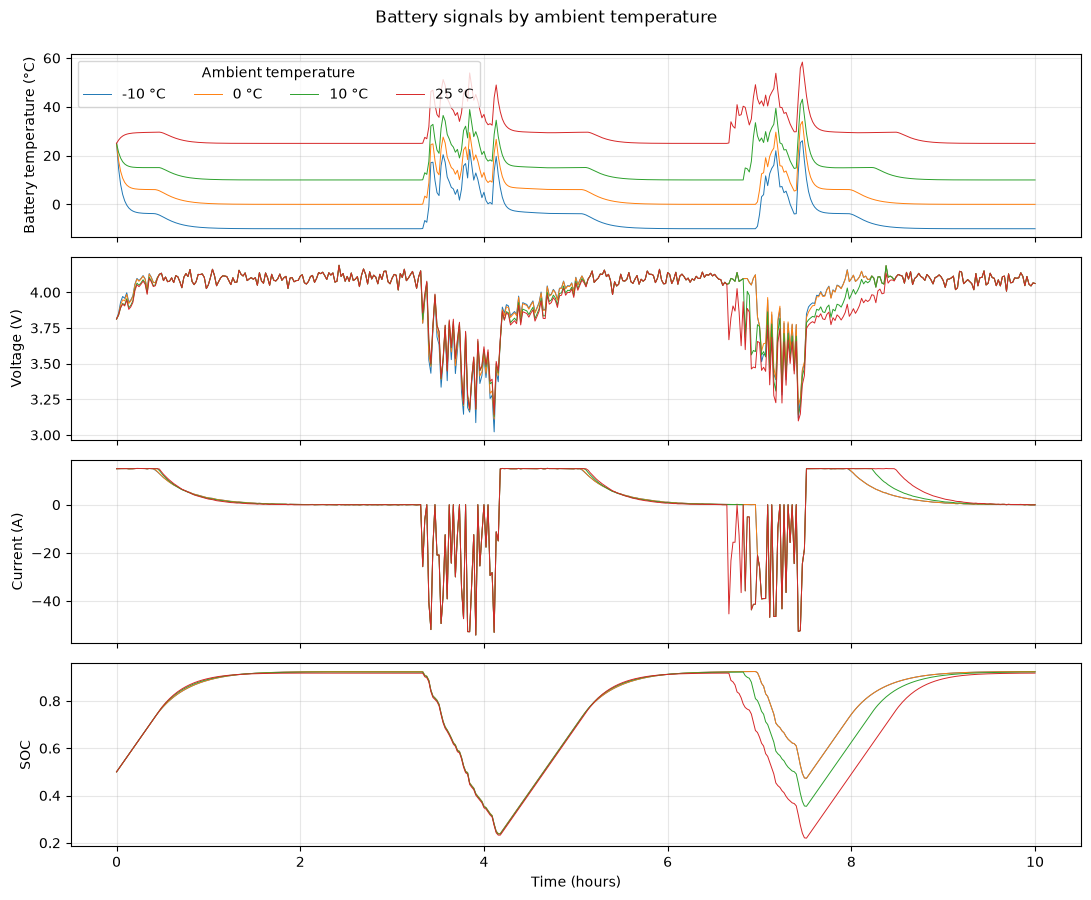

In [7]:
signals = ['temp_C', 'voltage_V', 'current_A', 'SOC']
y_labels = ['Battery temperature (°C)', 'Voltage (V)', 'Current (A)', 'SOC']

fig, axes = plt.subplots(len(signals), 1, figsize=(11, 9), sharex=True)

for ambient, run in battery_df.groupby('ambient_temp_C'):
    preview = run.iloc[::80]                  # every 80th sample (80 s)
    hours = preview['sample_index'] / 3600
    for ax, column in zip(axes, signals):
        ax.plot(hours, preview[column], label=f'{ambient} °C', linewidth=0.7)

for ax, label in zip(axes, y_labels):
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)

axes[0].legend(title='Ambient temperature', ncol=4)
axes[-1].set_xlabel('Time (hours)')
fig.suptitle('Battery signals by ambient temperature', y=0.995)
plt.tight_layout()
plt.show()

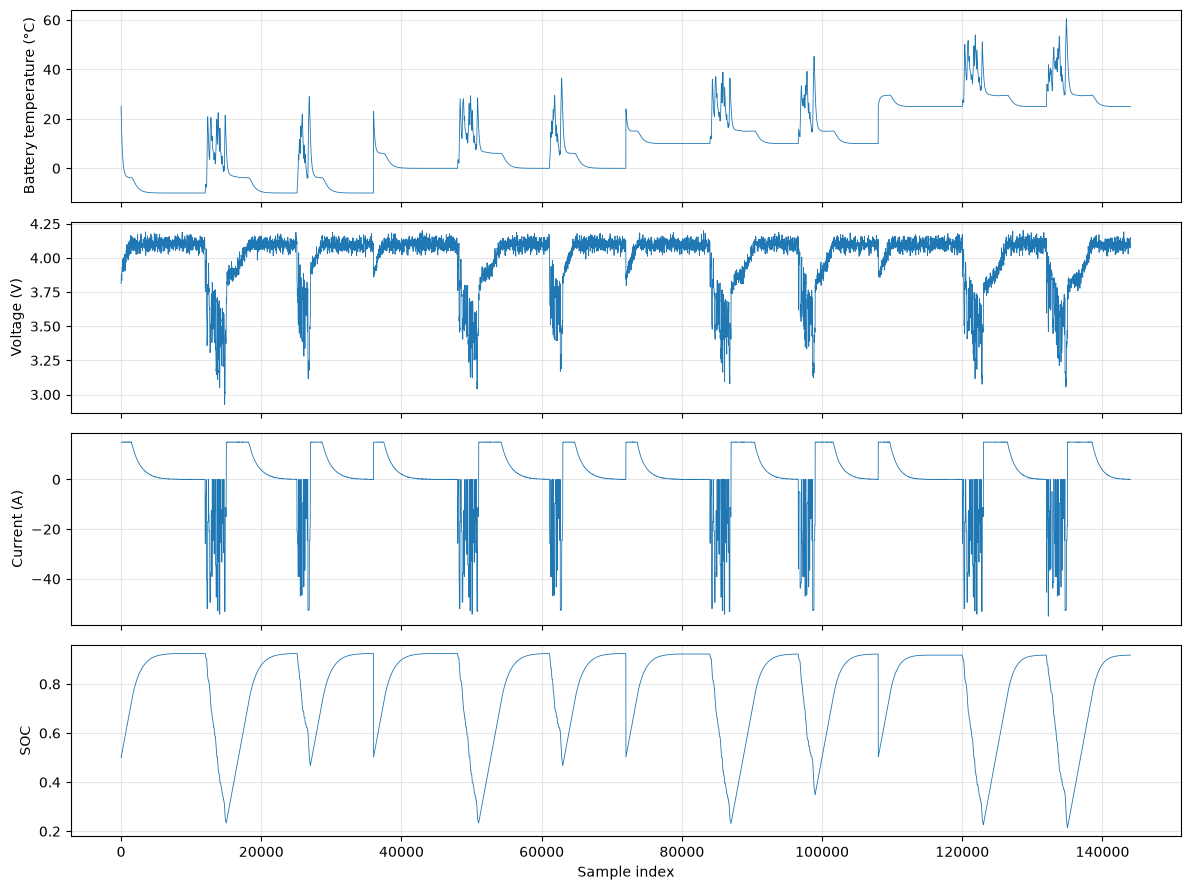

In [8]:
signals = ['temp_C', 'voltage_V', 'current_A', 'SOC']
y_labels = ['Battery temperature (°C)', 'Voltage (V)', 'Current (A)', 'SOC']

preview = battery_df.iloc[::20]             # every 20th sample to keep the figure light

fig, axes = plt.subplots(len(signals), 1, figsize=(12, 9), sharex=True)

for ax, column, label in zip(axes, signals, y_labels):
    ax.plot(preview.index, preview[column], linewidth=0.6)
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel('Sample index')
#fig.suptitle('Battery signals for the entire dataset', y=1.0)
plt.tight_layout()
plt.show()

## Model Training and evaluation

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split 
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.base import clone
from sklearn.preprocessing import MinMaxScaler

In [ ]:
features = ['temp_C', 'voltage_V', 'current_A']
X = battery_df[features]
y = battery_df['SOC']

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


## Polynomial regression 

In [27]:
poly_model = make_pipeline(MinMaxScaler(),PolynomialFeatures(degree=2), LinearRegression())
poly_model.fit(X_train, y_train) 
y_pred_test = poly_model.predict(X_test) 
y_pred_train = poly_model.predict(X_train)

rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
print(f"Test RMSE: {rmse_test:.10f}")

rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
print(f"Train RMSE: {rmse_train:.10f}")

Test RMSE: 0.0390613440
Train RMSE: 0.0390886518


## Decision Tree Regression

In [28]:
tree_model = make_pipeline(MinMaxScaler(), DecisionTreeRegressor(random_state=42))
tree_model.fit(X_train, y_train)
y_pred_test_tree = tree_model.predict(X_test)
y_pred_train_tree = tree_model.predict(X_train)

rmse_test_tree = np.sqrt(mean_squared_error(y_test, y_pred_test_tree))
print(f"Test RMSE (Tree): {rmse_test_tree:.10f}")

rmse_train_tree = np.sqrt(mean_squared_error(y_train, y_pred_train_tree))
print(f"Train RMSE (Tree): {rmse_train_tree:.10f}")

Test RMSE (Tree): 0.0101078695
Train RMSE (Tree): 0.0000000300


## Random Forest Regression

In [29]:
random_forest_model = make_pipeline(MinMaxScaler(), RandomForestRegressor(n_estimators=100, random_state=42))
random_forest_model.fit(X_train, y_train)
y_pred_test_rf = random_forest_model.predict(X_test)
y_pred_train_rf = random_forest_model.predict(X_train)

rmse_test_rf = np.sqrt(mean_squared_error(y_test, y_pred_test_rf))
print(f"Test RMSE (Random Forest): {rmse_test_rf:.10f}")

rmse_train_rf = np.sqrt(mean_squared_error(y_train, y_pred_train_rf))
print(f"Train RMSE (Random Forest): {rmse_train_rf:.10f}")

Test RMSE (Random Forest): 0.0065312667
Train RMSE (Random Forest): 0.0026406407


## Support vector Regression

In [31]:
svr_model = make_pipeline(MinMaxScaler(), SVR(kernel='rbf', C=100, gamma=0.1, epsilon=.1))
svr_model.fit(X_train, y_train)
y_pred_test_svr = svr_model.predict(X_test)
y_pred_train_svr = svr_model.predict(X_train)

rmse_test_svr = np.sqrt(mean_squared_error(y_test, y_pred_test_svr))
print(f"Test RMSE (SVR): {rmse_test_svr:.10f}")

rmse_train_svr = np.sqrt(mean_squared_error(y_train, y_pred_train_svr))
print(f"Train RMSE (SVR): {rmse_train_svr:.10f}")

Test RMSE (SVR): 0.0431610399
Train RMSE (SVR): 0.0430393760
